<div dir="rtl">

# סיכום ביניים

### אז מה למדנו עד עכשיו:

### 1. בשביל מה אנחנו עושים סימולציה.
### 2. מה מזינים לסימולציה?
### 3. בחירת זמן סימולציה בשביל דיוק.
### 4. חישוב warm up במקרה של ניתוח סטציונרי.
### 5. התפלגות מול תהליך עם תלות.
### 6. מיזוג ופיצול של תהליכים.
### 7. ניתוח תוצאות סימולציה: חישוב מדדים ופתרון בעיות עסקיות.

### במחברת זו נעשה ניתוח עסקי עבור מערכות תורים שונות וננסה לפתור בעיות שונות.

</div>


<div dir="rtl">

# הוספת מסלול במערכת תורים

### במחברת הזאת נבדוק מערכת תורים שבה לקוחות בוחרים מסלול לפי זמן צפוי.
### נתחיל מרשת עם שני מסלולים מקבילים.
### אחר כך נוסיף מסלול קצר מאוד בין שני צמתים פנימיים.
### בשלב הראשון רק נציג את המערכת ואת התוצאות.
### את הפירוש של התוצאה ניתן רק אחרי שנראה מה קרה מספרית.

</div>


In [1]:
import sys
import importlib

sys.path.append("../../code")

import utils
importlib.reload(utils)

from utils import (
    braess_queue_paradox_results,
    draw_braess_queue_network,
    plot_braess_queue_comparison,
)


<div dir="rtl">

## המערכת בלי המסלול הנוסף

### יש זרם כניסה חיצוני בקצב $\lambda=1$.
### יש שני מסלולים אפשריים מהכניסה ליציאה.
### במסלול העליון עוברים בתחנה $Q_1$ ואז בתחנה $F_1$.
### במסלול התחתון עוברים בתחנה $F_2$ ואז בתחנה $Q_2$.
### התחנות $Q_1,Q_2$ הן תורי $M/M/1$ עם קצב שירות $\mu=1.4$.
### התחנות $F_1,F_2$ הן תחנות שירות עם זמן שירות קבוע $2.6$.

</div>


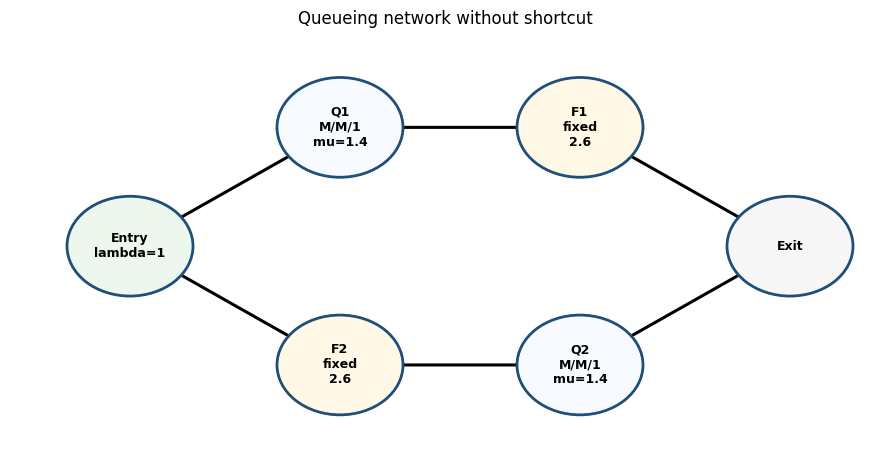

In [2]:
draw_braess_queue_network(include_shortcut=False)


<div dir="rtl">

## המערכת אחרי הוספת מסלול קצר

### עכשיו מוסיפים זרם מעבר קצר מאוד מהתחנה $Q_1$ אל התחנה $Q_2$.
### זמן המעבר במסלול החדש הוא רק $0.05$.
### לכן נוצרת אפשרות חדשה: לעבור דרך $Q_1$, להשתמש בקיצור, ואז לעבור דרך $Q_2$.
### כרגע לא נסביר אם זה טוב או רע. קודם נחשב.

</div>


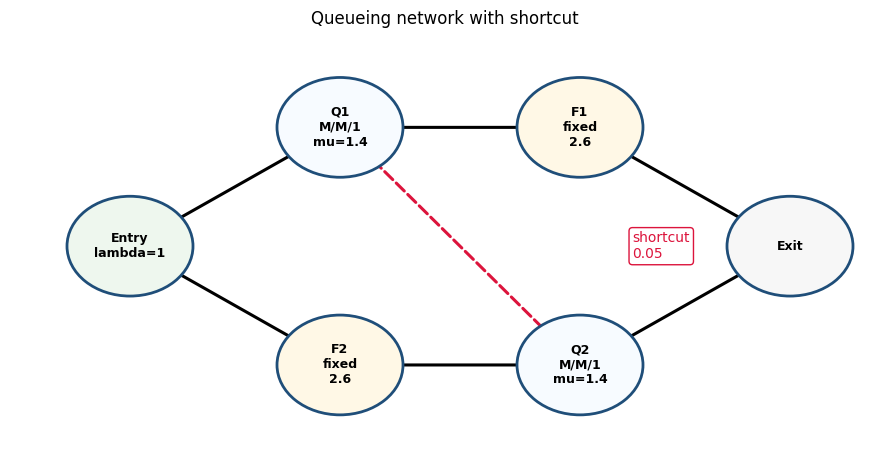

In [3]:
draw_braess_queue_network(include_shortcut=True)


<div dir="rtl">

## חישוב זמני המסלול

### עבור תור $M/M/1$, זמן השהייה הממוצע בתחנה הוא:
### $$W=\frac{1}{\mu-\lambda}$$
### זה כולל גם זמן המתנה בתור וגם זמן שירות.
### בלי המסלול הנוסף, בגלל הסימטריה, הזרם מתפצל שווה בשווה: $0.5$ בכל מסלול.
### עם המסלול הנוסף, המסלול דרך הקיצור מושך את כל הלקוחות, ולכן שתי תחנות התור $Q_1,Q_2$ מקבלות זרם $1$.

</div>


In [4]:
braess_results = braess_queue_paradox_results()
braess_results["parameters"]


,parameter,value
0,external arrival rate,1.00
1,Q1 service rate,1.40
2,Q2 service rate,1.40
3,fixed station delay F1,2.60
4,fixed station delay F2,2.60
5,shortcut delay,0.05


<div dir="rtl">

## תוצאות ברמת המערכת

### הטבלה הבאה משווה בין המערכת בלי המסלול הנוסף לבין המערכת עם המסלול הנוסף.
### המדד המרכזי הוא זמן ממוצע ללקוח בתוך הרשת.

</div>


In [5]:
braess_results["comparison"]


,network,active_route,flow_on_congested_queue_1,flow_on_congested_queue_2,mean_time_per_customer
0,without shortcut,top and bottom split equally,0.5,0.5,3.711111
1,with shortcut,all customers use shortcut route,1.0,1.0,5.050000


<div dir="rtl">

## תוצאות לפי מסלולים

### הטבלה הבאה מראה איזה מסלולים נמצאים בשימוש ומה זמן המסלול שלהם.
### במערכת עם המסלול הנוסף, שתי השורות האחרונות מראות מה היה קורה אם לקוח יחיד היה מנסה לסטות למסלול הישן.
### מכיוון שהסטייה אינה משפרת את הזמן שלו, כולם נשארים במסלול החדש.

</div>


In [6]:
braess_results["route_details"]


,network,route,status,route_flow,route_proportion,mean_time
0,without shortcut,Entry -> Q1 -> F1 -> Exit,used,0.5,0.5,3.711111
1,without shortcut,Entry -> F2 -> Q2 -> Exit,used,0.5,0.5,3.711111
2,with shortcut,Entry -> Q1 -> Shortcut -> Q2 -> Exit,used,1.0,1.0,5.050000
3,with shortcut,Entry -> Q1 -> F1 -> Exit,unused deviation check,0.0,0.0,5.100000
4,with shortcut,Entry -> F2 -> Q2 -> Exit,unused deviation check,0.0,0.0,5.100000


<div dir="rtl">

## פרופורציות הלקוחות במסלולים

### עכשיו נציג במפורש כמה לקוחות משתמשים בכל מסלול.
### הפרופורציה מחושבת מתוך הזרם במסלול חלקי הזרם הכולל:
### $$q_r=\frac{x_r}{\lambda}$$
### כאשר $x_r$ הוא קצב הזרם במסלול $r$, ו-$\lambda$ הוא קצב הכניסה הכולל למערכת.
### בדוגמה שלנו $\lambda=1$, ולכן הזרם והפרופורציה הם אותו מספר.
### בלי הקיצור, בגלל סימטריה ושוויון זמני המסלול, חצי מהלקוחות הולכים במסלול $Q_1 \to F_1$ וחצי הולכים במסלול $F_2 \to Q_2$.
### עם הקיצור, כל הלקוחות בוחרים במסלול $Q_1 \to Q_2$, ולכן הפרופורציה שלו היא $1$ והפרופורציות של שני המסלולים הישנים הן $0$.

</div>


In [7]:
braess_results["route_proportions"]


,network,route,status,route_flow,route_proportion
0,without shortcut,Entry -> Q1 -> F1 -> Exit,used,0.5,0.5
1,without shortcut,Entry -> F2 -> Q2 -> Exit,used,0.5,0.5
2,with shortcut,Entry -> Q1 -> Shortcut -> Q2 -> Exit,used,1.0,1.0
3,with shortcut,Entry -> Q1 -> F1 -> Exit,unused deviation check,0.0,0.0
4,with shortcut,Entry -> F2 -> Q2 -> Exit,unused deviation check,0.0,0.0


<div dir="rtl">

## איך מתקבלות הפרופורציות

### בלי הקיצור נסמן ב-$x$ את הזרם במסלול העליון.
### אז הזרם במסלול התחתון הוא $1-x$.
### זמן המסלול העליון הוא:
### $$T_{top}(x)=\frac{1}{1.4-x}+2.6$$
### זמן המסלול התחתון הוא:
### $$T_{bottom}(x)=2.6+\frac{1}{1.4-(1-x)}$$
### בשיווי משקל, שני המסלולים שנמצאים בשימוש צריכים להיות בעלי אותו זמן, ולכן $T_{top}(x)=T_{bottom}(x)$.
### בגלל הסימטריה מקבלים $x=0.5$.
### עם הקיצור, המסלול החדש משתמש בשני התורים $Q_1$ ו-$Q_2$.
### כאשר כל הזרם עובר בו, זמן המסלול החדש הוא $5.05$.
### אם לקוח יחיד ינסה לעבור לאחד המסלולים הישנים, הזמן שלו יהיה $5.1$.
### לכן אין לו תמריץ לסטות, וכל הלקוחות נשארים במסלול הקיצור.

</div>


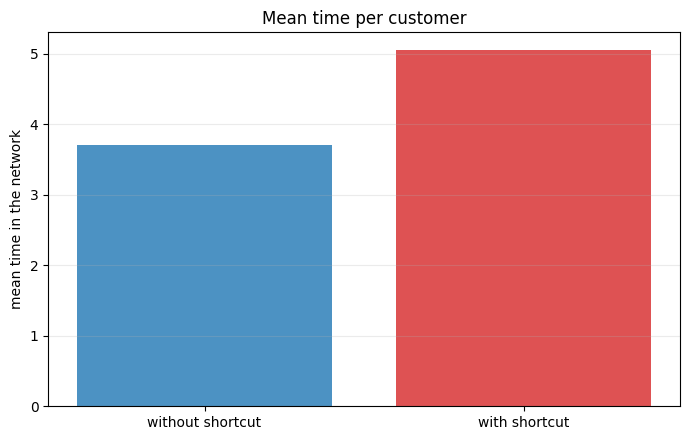

In [8]:
plot_braess_queue_comparison(braess_results)


<div dir="rtl">

## מה רואים בתוצאות

### בלי המסלול הנוסף, זמן ממוצע ללקוח הוא בערך $3.71$.
### אחרי הוספת המסלול הקצר, זמן ממוצע ללקוח הוא בערך $5.05$.
### כלומר הוספנו אפשרות מעבר חדשה, קצרה מאוד, אבל זמן השהייה הממוצע של הלקוחות גדל.
### זו התוצאה המפתיעה שרצינו לראות.

</div>


<div dir="rtl">

## ההסבר: Braess paradox

### התופעה הזאת נקראת Braess paradox.
### הפרדוקס אומר שהוספת קישור חדש לרשת יכולה להחמיר את ביצועי המערכת.
### הסיבה אינה שהקישור עצמו איטי. להפך, הקישור החדש בדוגמה כמעט מיידי.
### הבעיה היא שהוא משנה את בחירת המסלולים של הלקוחות.
### כל לקוח רואה מסלול שנראה לו טוב יותר באופן אישי: $Q_1 \to$ קיצור $\to Q_2$.
### אבל כאשר כולם עושים את אותה בחירה, שני התורים העמוסים $Q_1$ ו-$Q_2$ מקבלים את כל הזרם.
### התוצאה היא שהלקוחות ממתינים יותר, והמערכת כולה נהיית גרועה יותר.

</div>


<div dir="rtl">

## הקשר למערכות תורים

### במערכת תורים, לא מספיק לשאול אם הוספנו עוד אפשרות.
### צריך לבדוק איך האפשרות החדשה משנה את הזרמים ואת העומסים בתחנות.
### לפעמים מסלול חדש מושך לקוחות לתחנות שכבר רגישות לעומס.
### כאשר זה קורה, הקיבולת האפקטיבית של המערכת יכולה להיפגע למרות שהוספנו חיבור חדש.

</div>
